In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

# Dataset URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"

# Define column names based on auto-mpg.names
column_names = [
    'mpg', 'cylinders', 'displacement', 'horsepower', 
    'weight', 'acceleration', 'model_year', 'origin', 'car_name'
]

# Load directly from URL using whitespace separator
df = pd.read_csv(url, sep=r'\s+', names=column_names)

# Display first 5 rows to confirm
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,1,ford torino


In [2]:
# Clean horsepower
df['horsepower'] = df['horsepower'].replace('?', np.nan)
df['horsepower'] = pd.to_numeric(df['horsepower'])

# Map origin
origin_map = {1: 'USA', 2: 'Asia', 3: 'Europe'}
df['origin'] = df['origin'].map(origin_map)

# Check the cleaned DataFrame
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name
0,18.0,8,307.0,130.0,3504.0,12.0,70,USA,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693.0,11.5,70,USA,buick skylark 320
2,18.0,8,318.0,150.0,3436.0,11.0,70,USA,plymouth satellite
3,16.0,8,304.0,150.0,3433.0,12.0,70,USA,amc rebel sst
4,17.0,8,302.0,140.0,3449.0,10.5,70,USA,ford torino


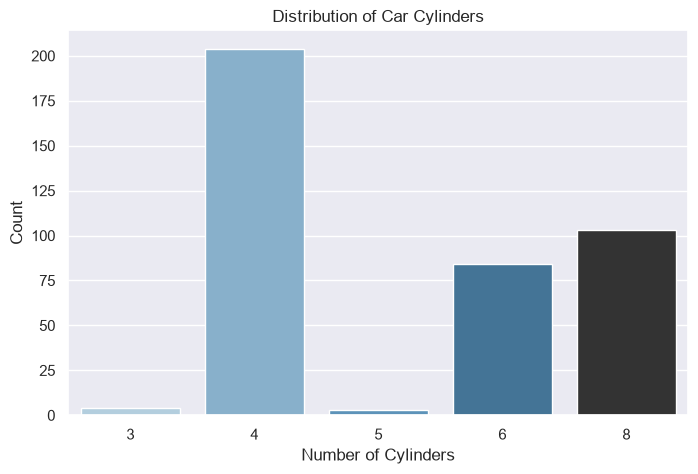

In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='cylinders', hue='cylinders', palette='Blues_d', legend=False)
plt.title('Distribution of Car Cylinders')
plt.xlabel('Number of Cylinders')
plt.ylabel('Count')
plt.show()

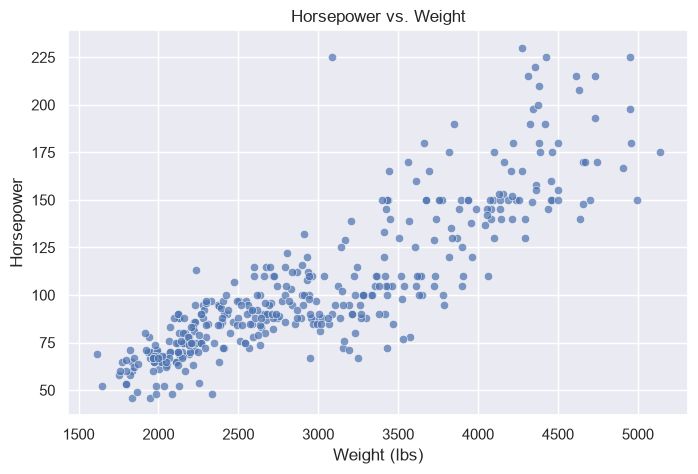

In [4]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='weight', y='horsepower', alpha=0.7)
plt.title('Horsepower vs. Weight')
plt.xlabel('Weight (lbs)')
plt.ylabel('Horsepower')
plt.show()

**Question:** How does vehicle origin affect the relationship between horsepower and weight?

**Answer:** Across all regions, heavier cars generally have higher horsepower. However, US-made cars dominate the heavy, high-horsepower category, whereas European and Asian imports are concentrated primarily in the lighter, lower-horsepower categories.

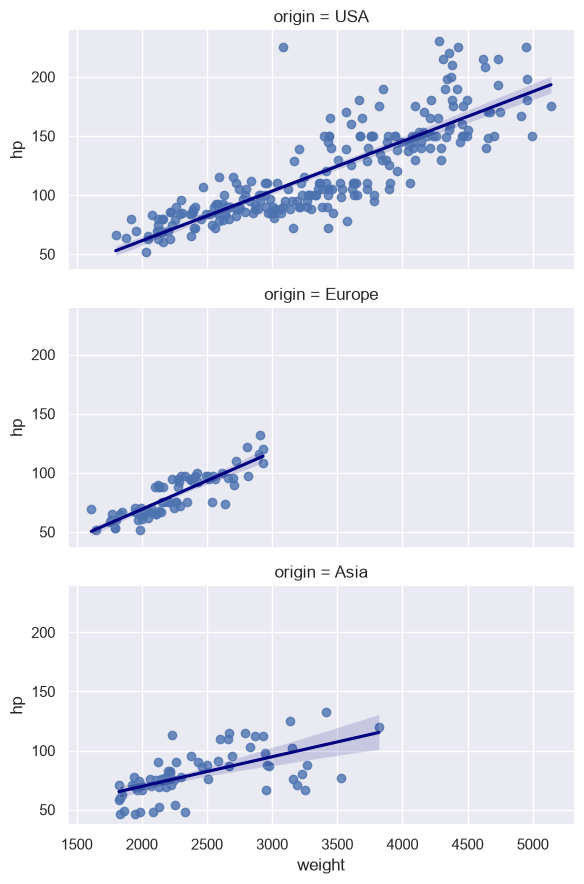

In [5]:
g = sns.lmplot(
    data=df, 
    x='weight', 
    y='horsepower', 
    row='origin', 
    aspect=2, 
    height=3,
    line_kws={'color': 'navy'}
)
g.set_axis_labels('weight', 'hp')
plt.show()